# Ranging and Ransac

We'll use the following imports:

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from sklearn import linear_model

If you get an error from importing sklearn, then you will have to install it using:
conda install scikit-learn

For the exercise we will be using the data taken from a lidar by a robot in a hallway. The data is saved in `laser.csv` and we can import this in Python using numpy as such:

In [5]:
laser = np.genfromtxt('laser.csv', delimiter=',')

The file contains only a single rotation of the lidar. You can open the file in any text editor to get a look at the data. Each number in the file is the distance measured in meters. The lidar starts measuring at 135 degrees and ends at -135 degrees and it rotates the same amount between each measurement. 

## Exercise 3.1
Convert the data in the csv file to x and y coordinates in a Carthesian coordinate system and plot the result using matplotlib.

Hint: Use [scatter](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) instead of plt.plot in order to show every measurement as a point. 

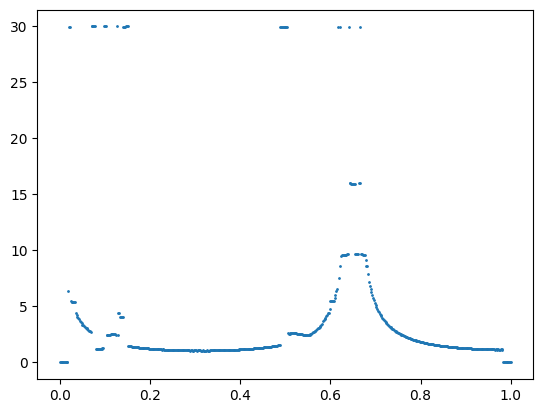

In [29]:
# Convert to x and y coordinates

x = np.linspace(0, 1, laser.shape[0])
plt.scatter(x, laser, s=1, label='Laser 1')
#plt.plot(x,laser, 'r.', label='Laser 1')

## Exercise 3.2

We would like to locate one of the walls in the dataset. To do so we will use [Ransac](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.RANSACRegressor.html) to fine the best line fit in the noisy data. A Ransac regressor is initialized the following way using sklearn:

In [30]:
degree = 3
ransac = linear_model.RANSACRegressor(
    min_samples=degree + 1,
    random_state=0
)

Now that we have our Ransac regressor we can fit it to a dataset (x,y):

In [31]:
# Fit data
ransac.fit(x.reshape(-1, 1), laser)

,estimator,None
,min_samples,4
,residual_threshold,None
,is_data_valid,None
,is_model_valid,None
,max_trials,100
,max_skips,inf
,stop_n_inliers,inf
,stop_score,inf
,stop_probability,0.99
,loss,'absolute_error'


Finally, to get the fitted line we can use the predict function. As an argument this takes the x values in which the line will be predicted:

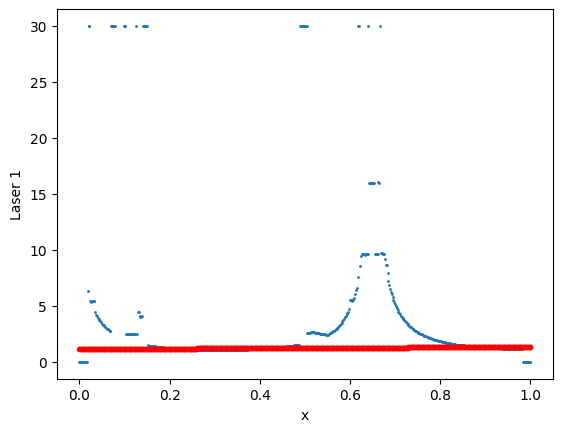

In [33]:
# Predict line
ransac_y = ransac.predict(x.reshape(-1, 1))
fig, ax = plt.subplots()
ax.plot(x, ransac_y, 'r.', label='RANSAC regressor')
ax.set_xlabel('x')
ax.set_ylabel('Laser 1')
ax.scatter(x, laser, s=1, label='Laser 1')

Plot the line on top of the scatterplot from before to see the fit.

## Exercise 3.3

To see which data points were used to make the line fit and which were deemed outliers, we can use the function ransac.inlier_mask_

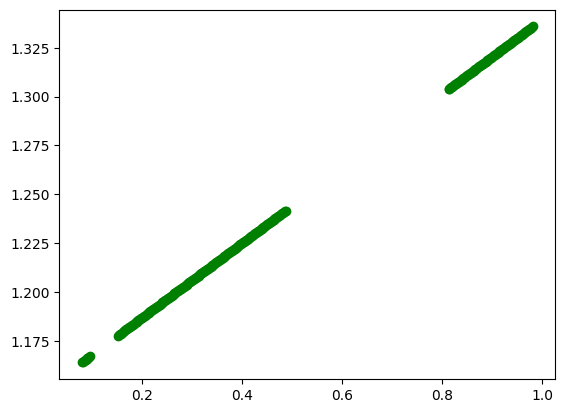

In [35]:
plt.scatter(x[ransac.inlier_mask_], ransac_y[ransac.inlier_mask_], color='green')

Find the second hallway wall using another Ransac fit and plot it together with the data points and the first ransac fit.

Hint: Use the outliers from the first Ransac.

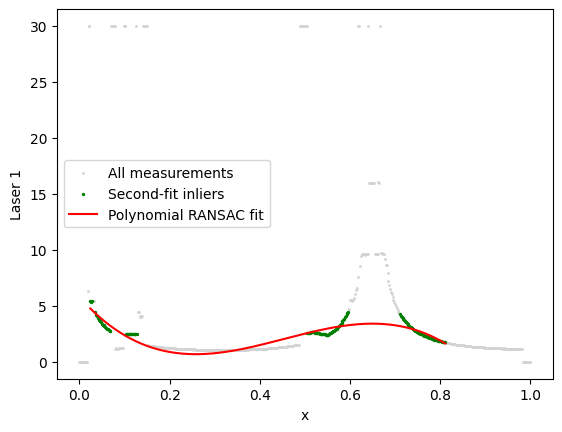

In [45]:
ransac2 = linear_model.RANSACRegressor()

# Find the second hallway wall
#masking data
laser_masked = np.ma.masked_array(laser, mask=ransac.inlier_mask_)
x_masked = np.ma.masked_array(x, mask=ransac.inlier_mask_)

# Fit data
ransac2.fit(x.reshape(-1, 1), laser_masked)

#predict line
ransac2_y = ransac2.predict(x_masked.reshape(-1, 1))

fig, ax = plt.subplots()
ax.plot(x_masked, ransac2_y, 'r.', label='RANSAC regressor 2')
ax.set_xlabel('x')
ax.set_ylabel('Laser 1 (outliers)')
plt.scatter(x, laser_masked, s=1, label='Laser 1 (outliers)')
plt.legend()